In [296]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

Pandas: 3.0.5
NumPy: 2.4.6
Scikit-learn: 1.9.0
Matplotlib: 3.11.1
Seaborn: 0.13.2


In [297]:
df_train = pd.read_csv("D:\datasets\Adult/adult_train.csv")
df_test = pd.read_csv("D:\datasets\Adult/adult_test.csv")

Cleaning Dateset Here

In [298]:
df = df_train
# # df = df_train.sample(10, random_state=42)
# # df.rename("Race", "Face")
# df

In [299]:
df.shape

(32561, 15)

In [300]:
df.tail(5)

,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country,Target
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K
32560,52,Self-emp-inc,287927,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,15024,0,40,United-States,>50K


In [301]:
df.columns

Index(['Age', 'Workclass', 'fnlwgt', 'Education', 'Education_Num',
       'Martial_Status', 'Occupation', 'Relationship', 'Race', 'Sex',
       'Capital_Gain', 'Capital_Loss', 'Hours_per_week', 'Country', 'Target'],
      dtype='str')

In [302]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Age             32561 non-null  int64
 1   Workclass       30725 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   Education       32561 non-null  str  
 4   Education_Num   32561 non-null  int64
 5   Martial_Status  32561 non-null  str  
 6   Occupation      30718 non-null  str  
 7   Relationship    32561 non-null  str  
 8   Race            32561 non-null  str  
 9   Sex             32561 non-null  str  
 10  Capital_Gain    32561 non-null  int64
 11  Capital_Loss    32561 non-null  int64
 12  Hours_per_week  32561 non-null  int64
 13  Country         31978 non-null  str  
 14  Target          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 3.7 MB


In [303]:
df["Target"].head(10)


0     <=50K
1     <=50K
2     <=50K
3     <=50K
4     <=50K
5     <=50K
6     <=50K
7      >50K
8      >50K
9      >50K
Name: Target, dtype: str

In [304]:
df["Target"].value_counts()

Target
<=50K    24720
>50K      7841
Name: count, dtype: int64

In [305]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
Education_Num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
Capital_Gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
Capital_Loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
Hours_per_week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [306]:
df.describe(include="all")

,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country,Target
count,32561.000000,30725,3.256100e+04,32561,32561.000000,32561,30718,32561,32561,32561,32561.000000,32561.000000,32561.000000,31978,32561
unique,NaN,8,NaN,16,NaN,7,14,6,5,2,NaN,NaN,NaN,41,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [307]:
df.describe(include="object")

C:\Users\asdfg\AppData\Local\Temp\ipykernel_7736\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Workclass,Education,Martial_Status,Occupation,Relationship,Race,Sex,Country,Target
count,30725,32561,32561,30718,32561,32561,32561,31978,32561
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22696,10501,14976,4140,13193,27816,21790,29170,24720


In [308]:
sum(df.isnull().mean()*100)

13.089278584810048

In [309]:


df.isnull().mean()*100

Age               0.000000
Workclass         5.638647
fnlwgt            0.000000
Education         0.000000
Education_Num     0.000000
Martial_Status    0.000000
Occupation        5.660146
Relationship      0.000000
Race              0.000000
Sex               0.000000
Capital_Gain      0.000000
Capital_Loss      0.000000
Hours_per_week    0.000000
Country           1.790486
Target            0.000000
dtype: float64

In [310]:
for col in ["Country", "Workclass", "Occupation"]:
    df[col] = df[col].fillna(df[col].mode()[0])

In [311]:


df.isnull().mean()*100

Age               0.0
Workclass         0.0
fnlwgt            0.0
Education         0.0
Education_Num     0.0
Martial_Status    0.0
Occupation        0.0
Relationship      0.0
Race              0.0
Sex               0.0
Capital_Gain      0.0
Capital_Loss      0.0
Hours_per_week    0.0
Country           0.0
Target            0.0
dtype: float64

In [312]:
df.value_counts()

Age  Workclass     fnlwgt  Education     Education_Num  Martial_Status      Occupation         Relationship   Race                Sex     Capital_Gain  Capital_Loss  Hours_per_week  Country        Target
25   Private       195994  1st-4th       2              Never-married       Priv-house-serv    Not-in-family  White               Female  0             0             40              Guatemala      <=50K     3
90   Private       52386   Some-college  10             Never-married       Other-service      Not-in-family  Asian-Pac-Islander  Male    0             0             35              United-States  <=50K     2
19   Private       251579  Some-college  10             Never-married       Other-service      Own-child      White               Male    0             0             14              United-States  <=50K     2
25   Private       308144  Bachelors     13             Never-married       Craft-repair       Not-in-family  White               Male    0             0             40 

In [313]:
(df == "?").sum()
# (df == "").sum()

Age               0
Workclass         0
fnlwgt            0
Education         0
Education_Num     0
Martial_Status    0
Occupation        0
Relationship      0
Race              0
Sex               0
Capital_Gain      0
Capital_Loss      0
Hours_per_week    0
Country           0
Target            0
dtype: int64

In [314]:
df.duplicated().sum()

np.int64(24)

In [315]:
df = df.drop_duplicates()

In [316]:

df[df.duplicated()]

,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country,Target


In [317]:
df["Education"].unique()

<StringArray>
[   ' Bachelors',      ' HS-grad',         ' 11th',      ' Masters',
          ' 9th', ' Some-college',   ' Assoc-acdm',    ' Assoc-voc',
      ' 7th-8th',    ' Doctorate',  ' Prof-school',      ' 5th-6th',
         ' 10th',      ' 1st-4th',    ' Preschool',         ' 12th']
Length: 16, dtype: str

In [318]:
df["Education"].nunique()

16

In [319]:
df["Education"].value_counts()

Education
HS-grad         10494
Some-college     7282
Bachelors        5353
Masters          1722
Assoc-voc        1382
11th             1175
Assoc-acdm       1067
10th              933
7th-8th           645
Prof-school       576
9th               514
12th              433
Doctorate         413
5th-6th           332
1st-4th           166
Preschool          50
Name: count, dtype: int64

In [320]:
df["Target"].value_counts()

Target
<=50K    24698
>50K      7839
Name: count, dtype: int64

In [321]:
df["Target"].value_counts(normalize=True)*100

Target
<=50K    75.907428
>50K     24.092572
Name: proportion, dtype: float64

In [322]:
df.dtypes

Age               int64
Workclass           str
fnlwgt            int64
Education           str
Education_Num     int64
Martial_Status      str
Occupation          str
Relationship        str
Race                str
Sex                 str
Capital_Gain      int64
Capital_Loss      int64
Hours_per_week    int64
Country             str
Target              str
dtype: object

In [323]:
numaricle_columns = df.select_dtypes(include=["int64", "float64"]).columns
print(numaricle_columns)

Index(['Age', 'fnlwgt', 'Education_Num', 'Capital_Gain', 'Capital_Loss',
       'Hours_per_week'],
      dtype='str')


In [324]:
categorical_columns = df.select_dtypes(include="str").columns
print(categorical_columns)


Index(['Workclass', 'Education', 'Martial_Status', 'Occupation',
       'Relationship', 'Race', 'Sex', 'Country', 'Target'],
      dtype='str')


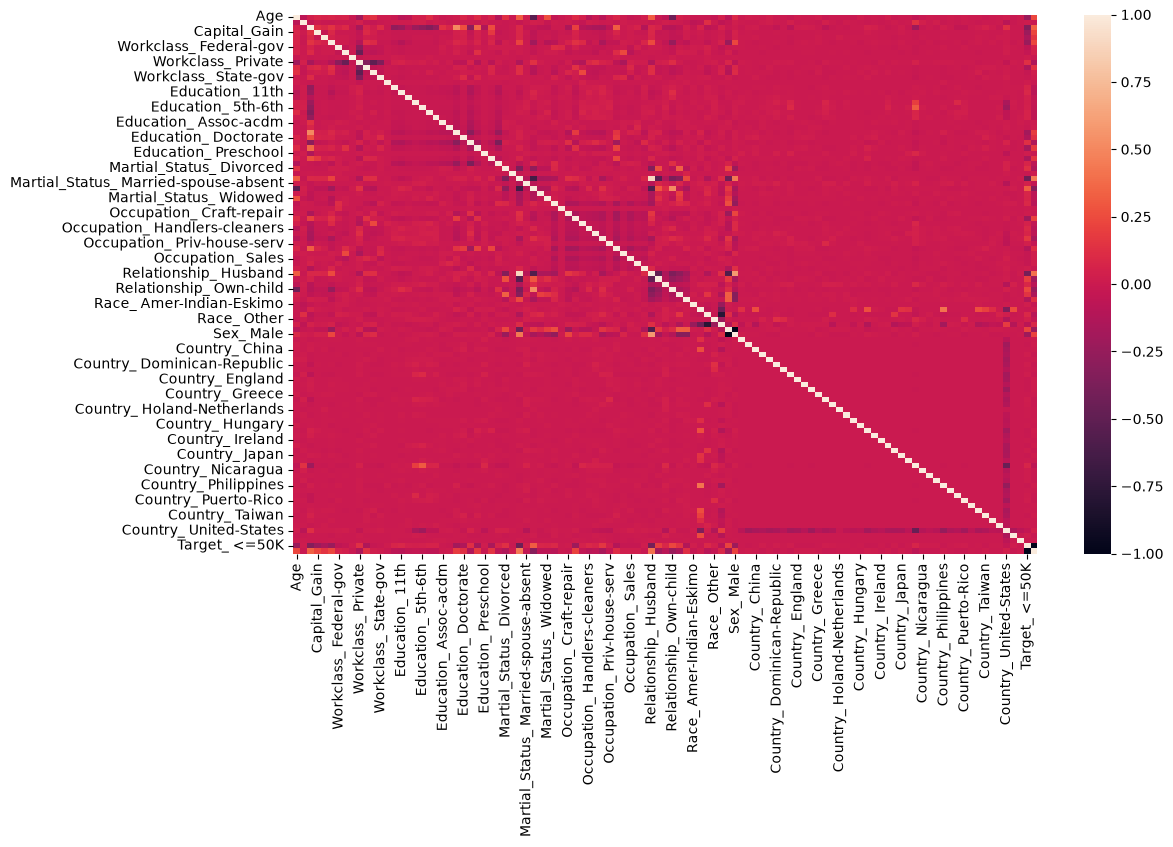

In [325]:
all_colums = pd.get_dummies(df, dtype=int)
plt.figure(figsize=(12,7))
sns.heatmap(all_colums.corr(), annot=False)
plt.show()

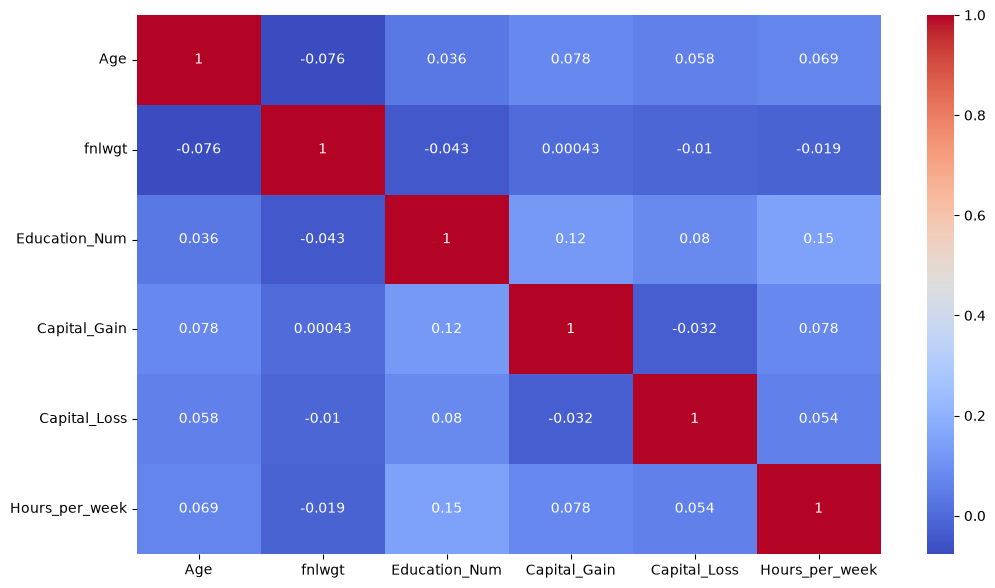

In [326]:
plt.figure(figsize=(12,7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

In [327]:
df.corr(numeric_only=True)

,Age,fnlwgt,Education_Num,Capital_Gain,Capital_Loss,Hours_per_week
Age,1.000000,-0.076447,0.036224,0.077676,0.057745,0.068515
fnlwgt,-0.076447,1.000000,-0.043388,0.000429,-0.010260,-0.018898
Education_Num,0.036224,-0.043388,1.000000,0.122664,0.079892,0.148422
Capital_Gain,0.077676,0.000429,0.122664,1.000000,-0.031639,0.078408
Capital_Loss,0.057745,-0.010260,0.079892,-0.031639,1.000000,0.054229
Hours_per_week,0.068515,-0.018898,0.148422,0.078408,0.054229,1.000000


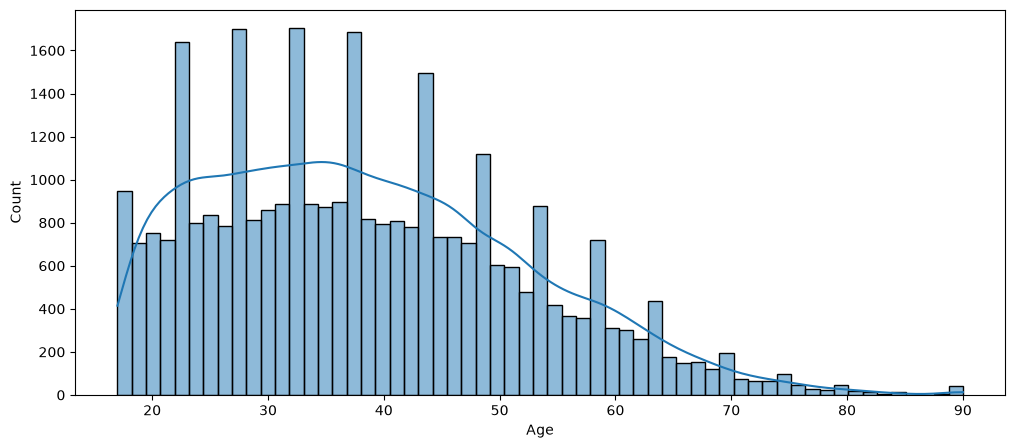

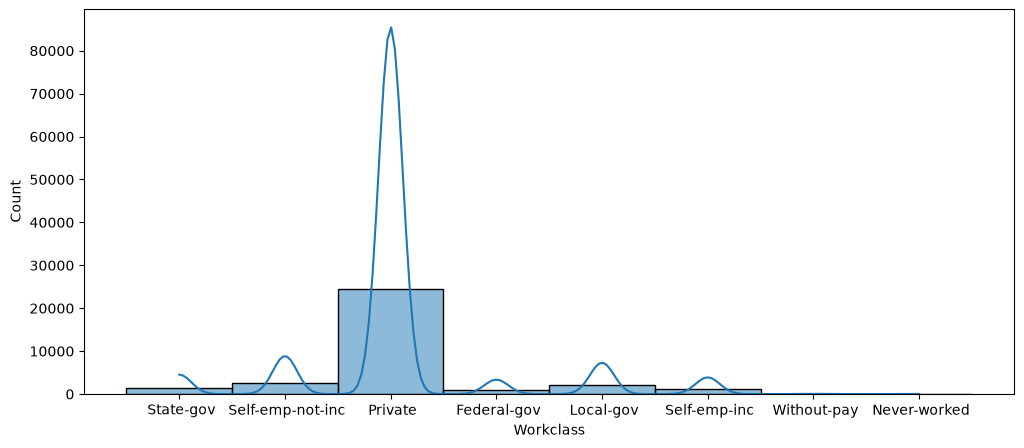

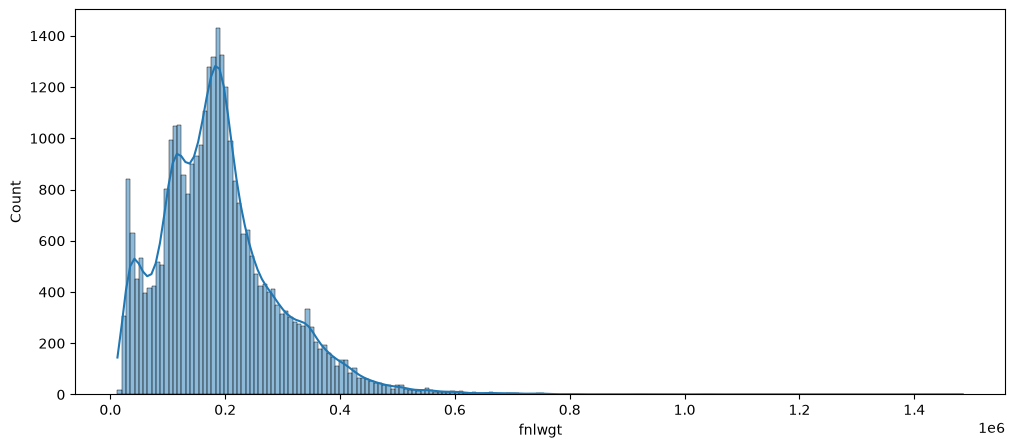

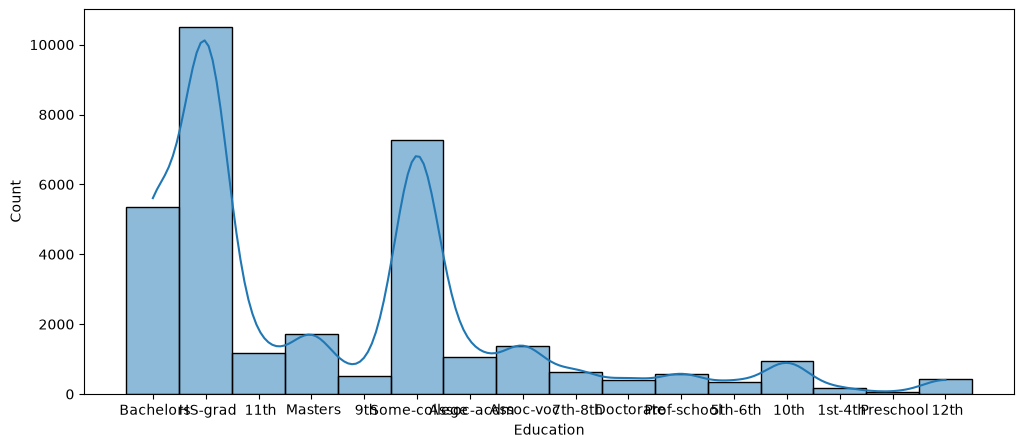

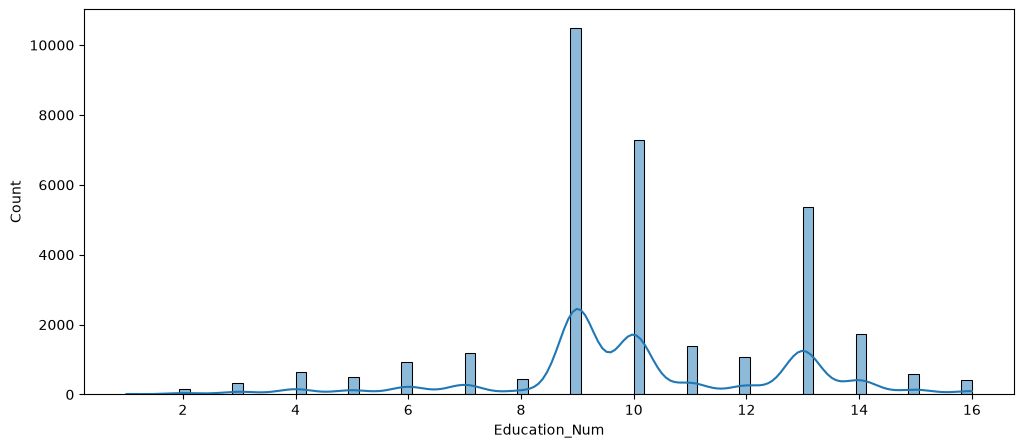

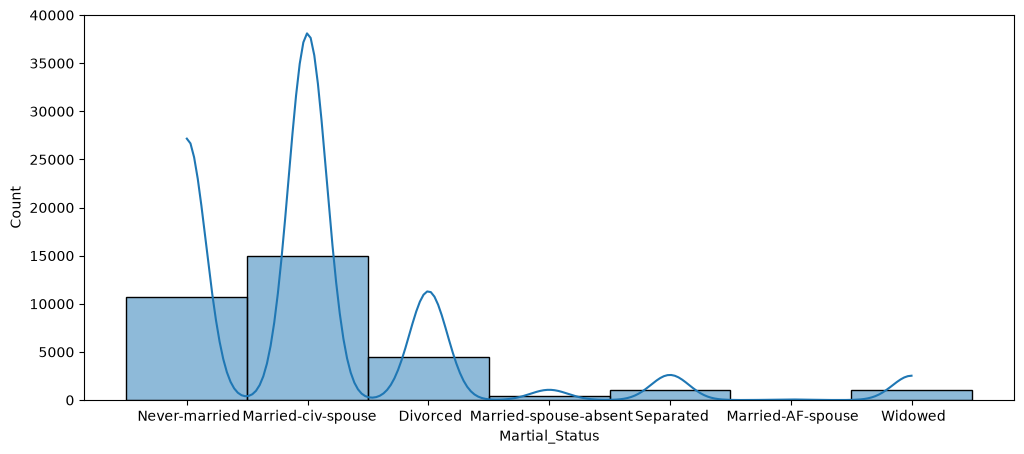

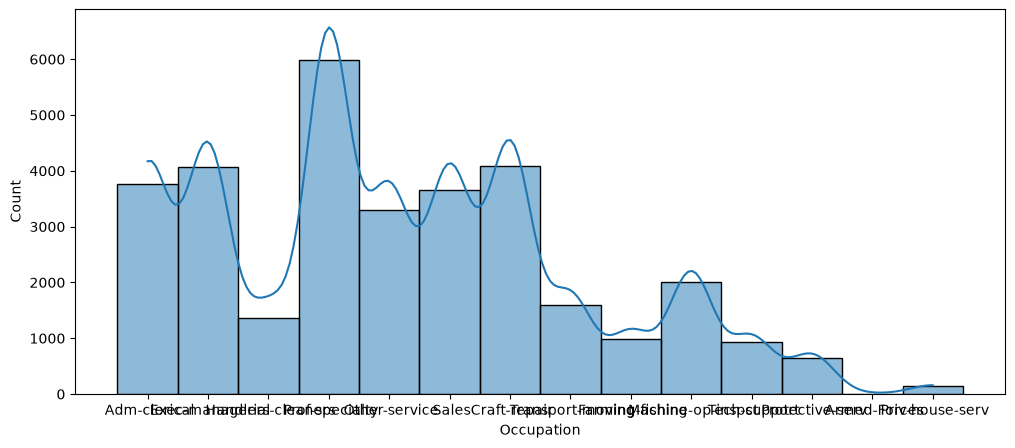

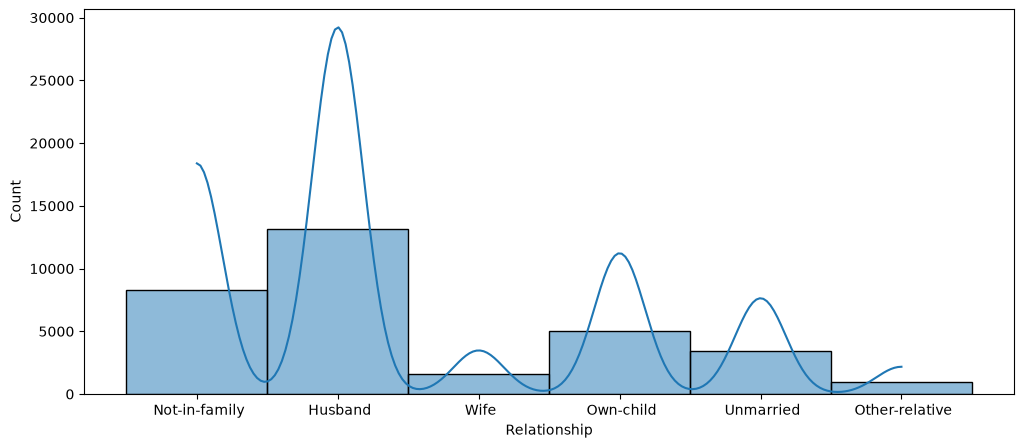

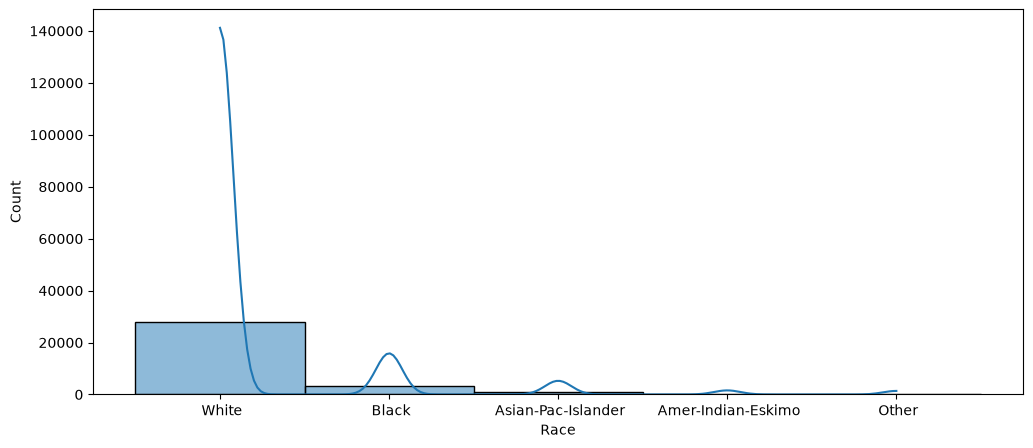

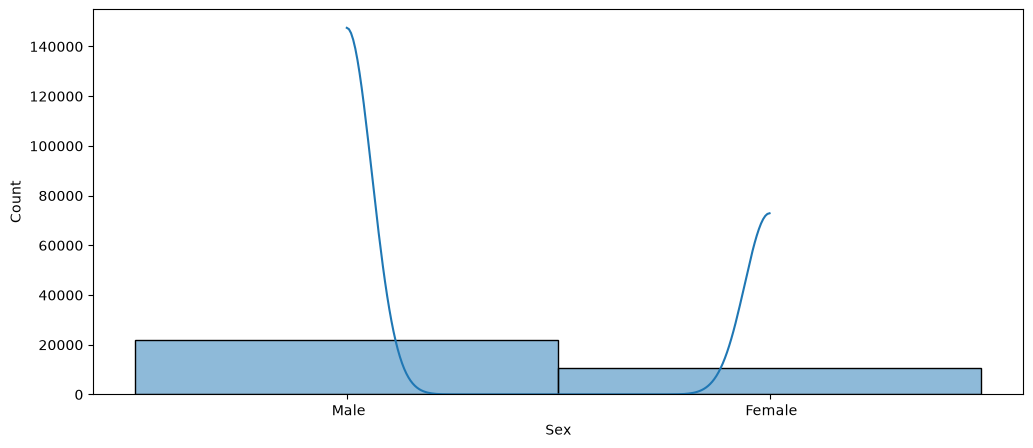

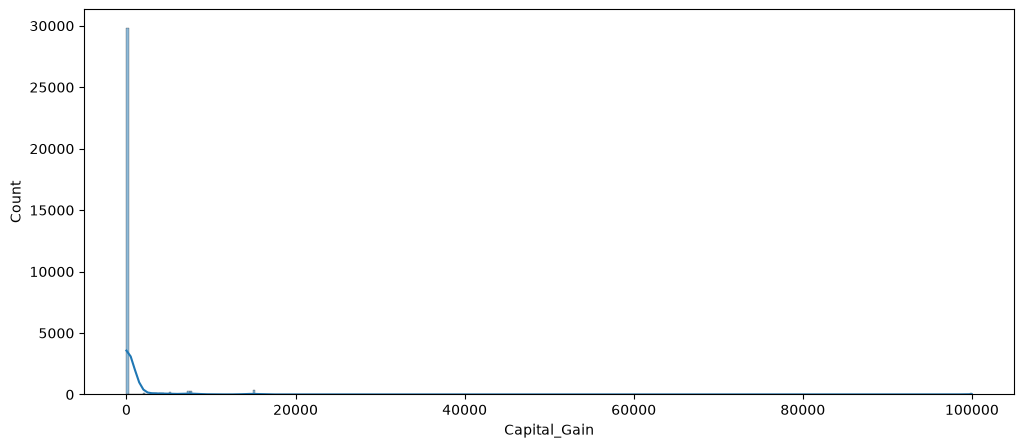

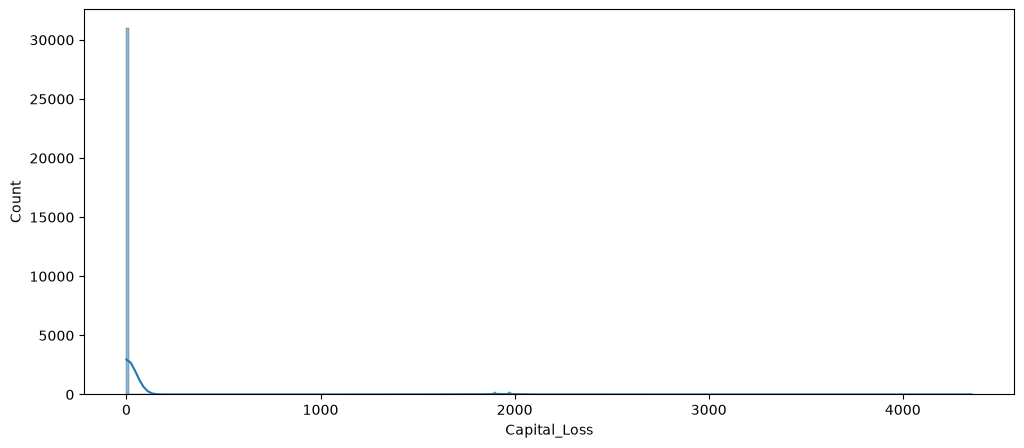

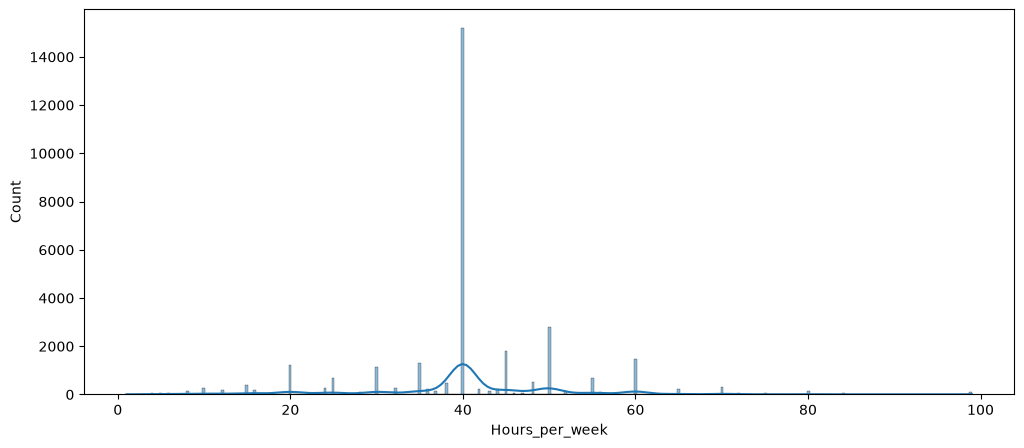

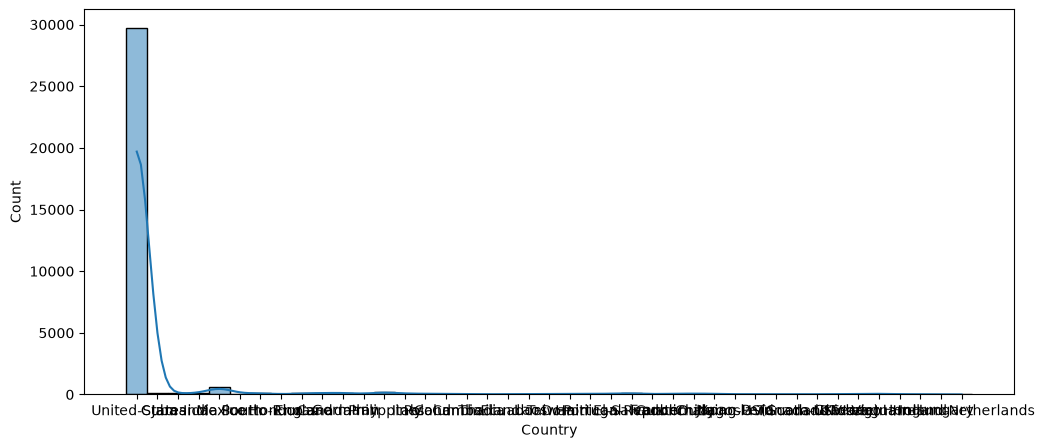

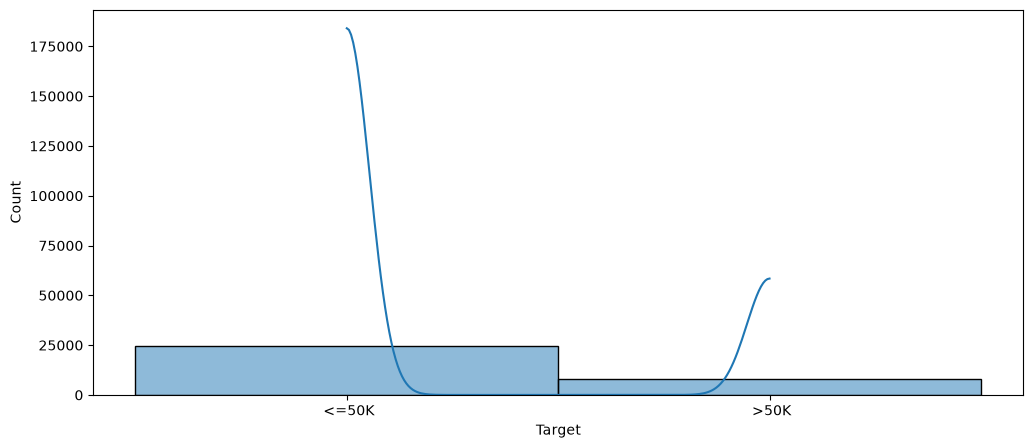

In [328]:
for column in df.columns:
    plt.figure(figsize=(12,5))
    sns.histplot(data=df, x=column, kde=True)
    plt.show()

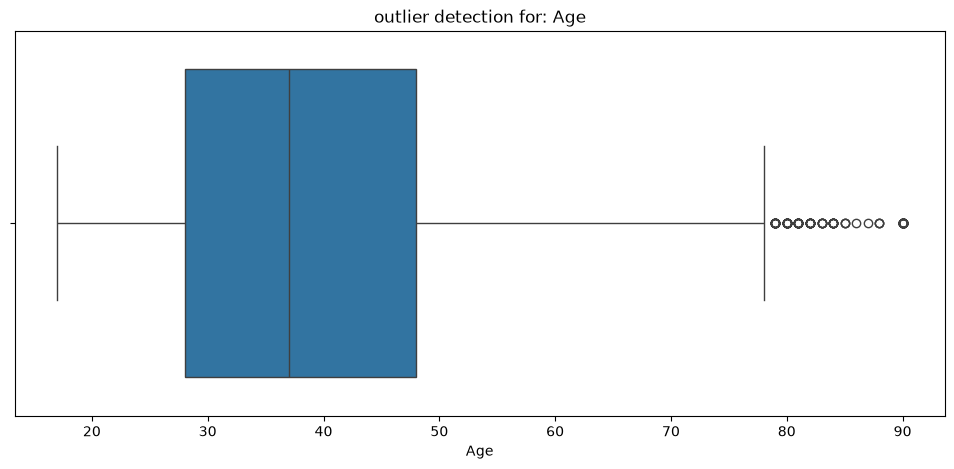

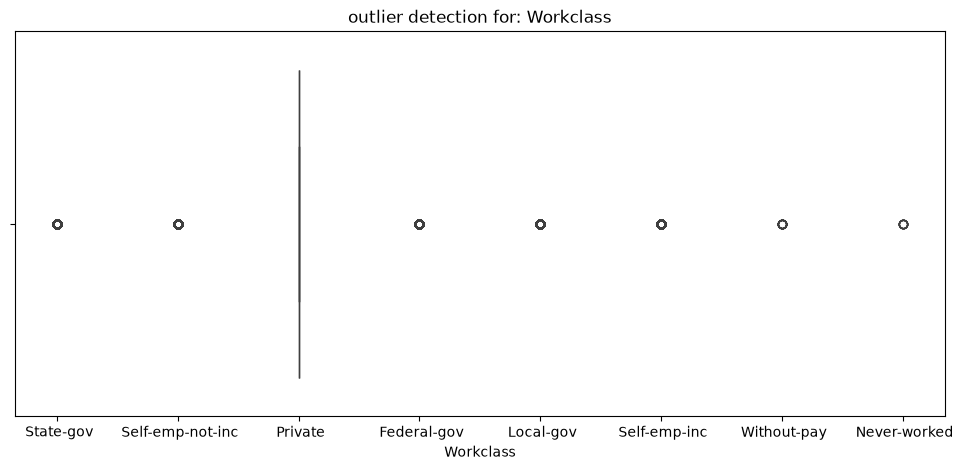

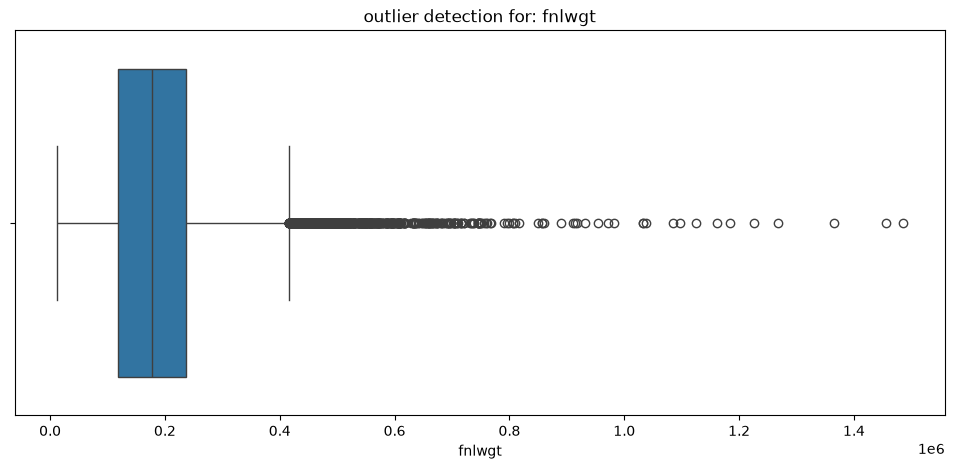

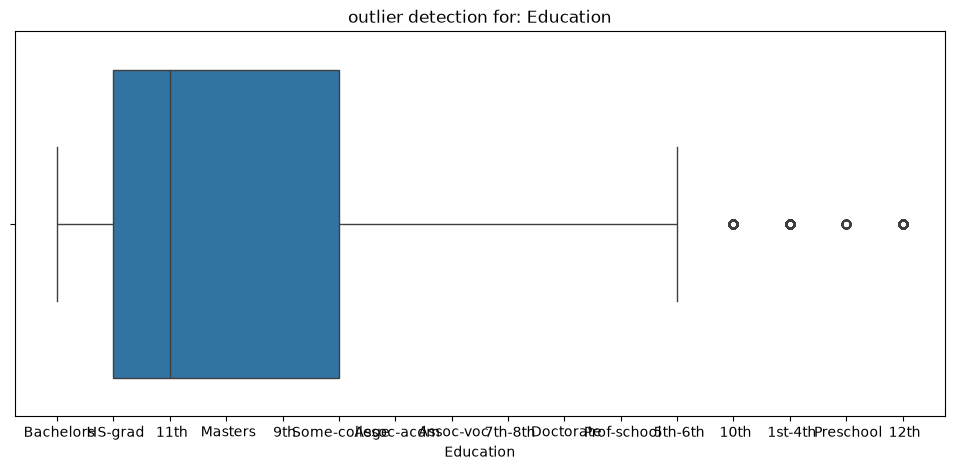

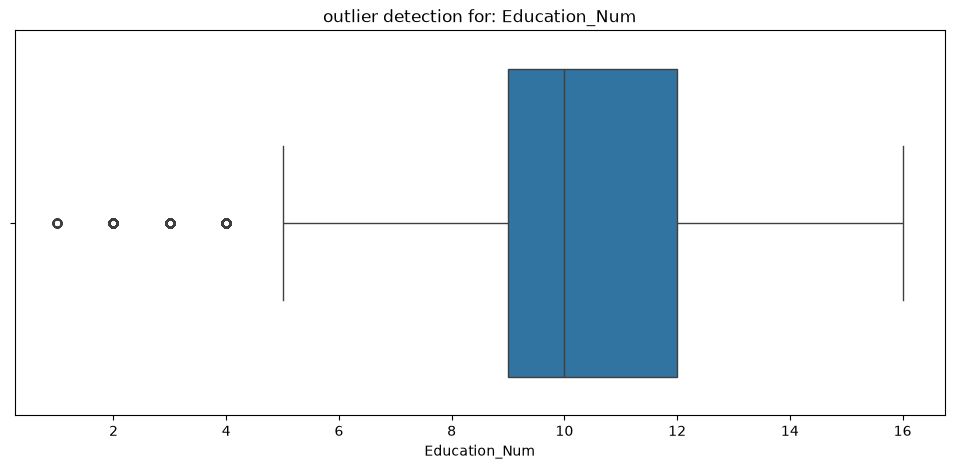

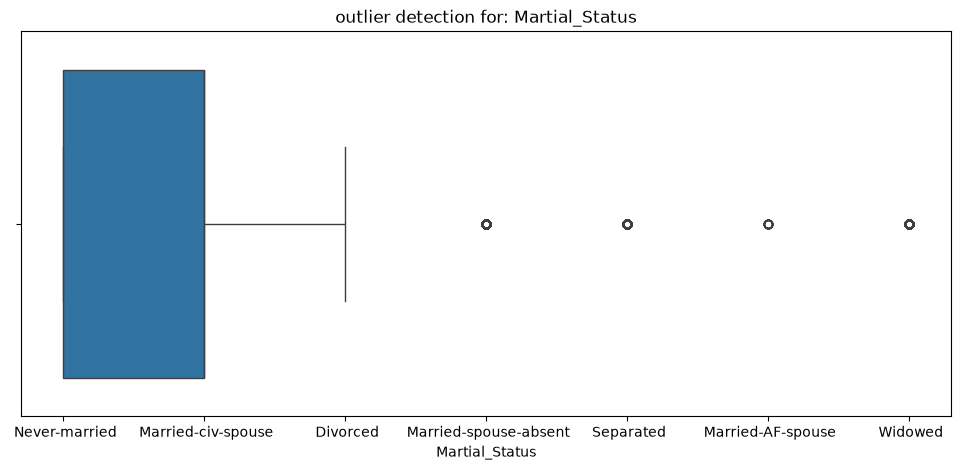

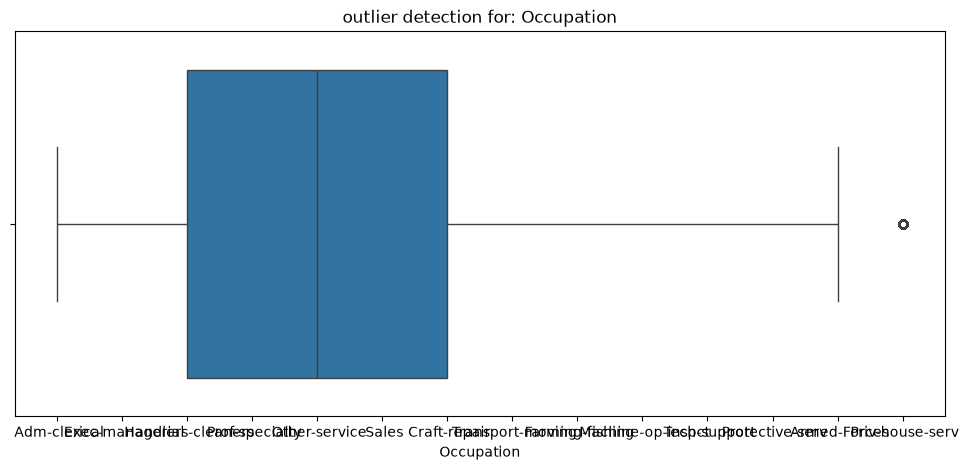

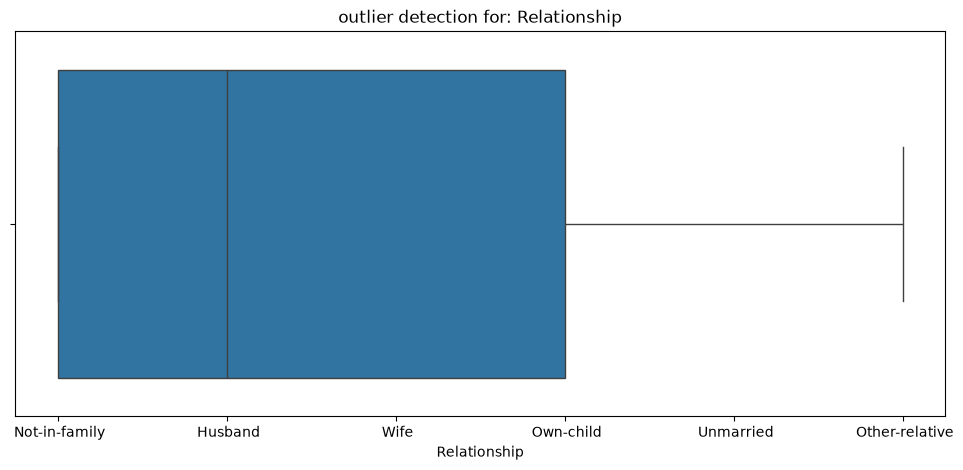

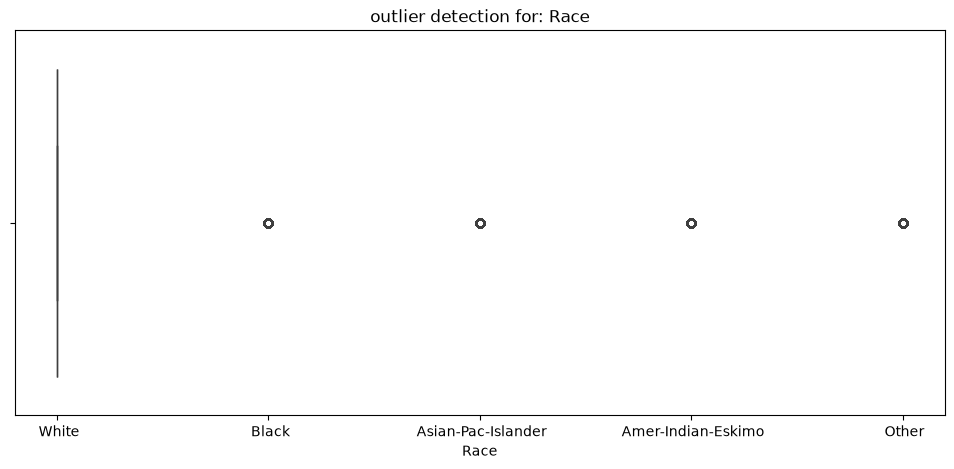

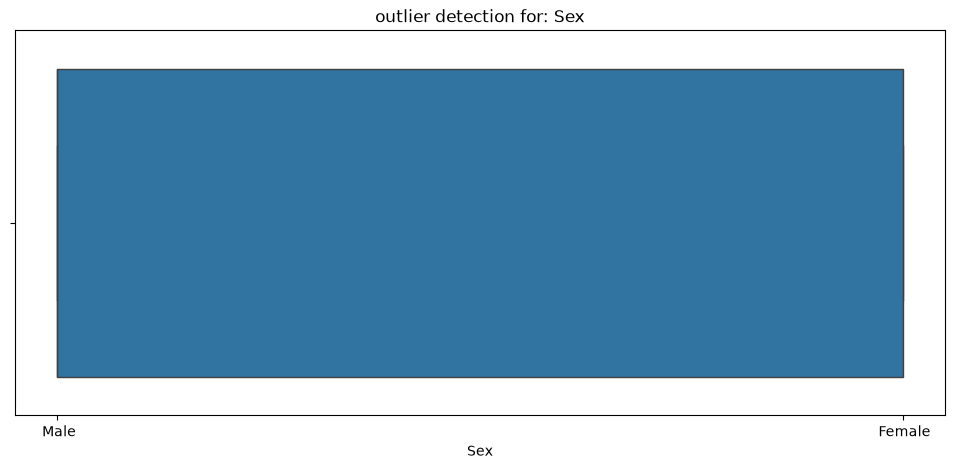

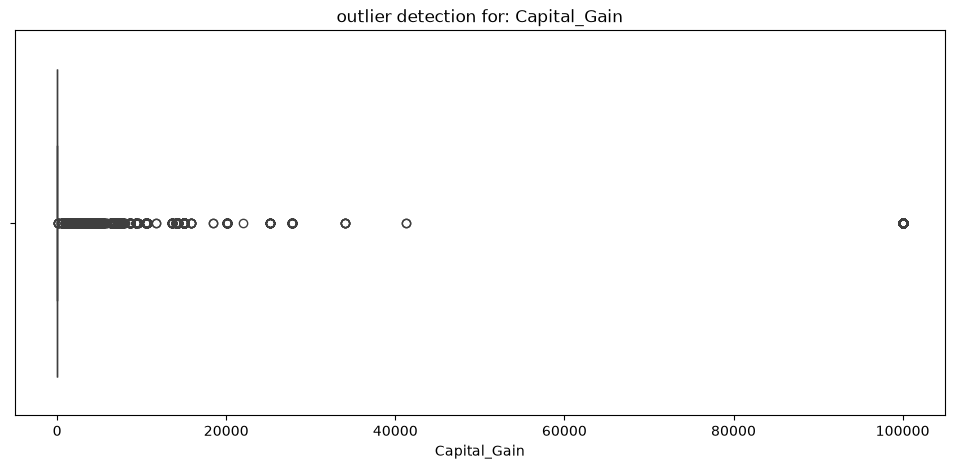

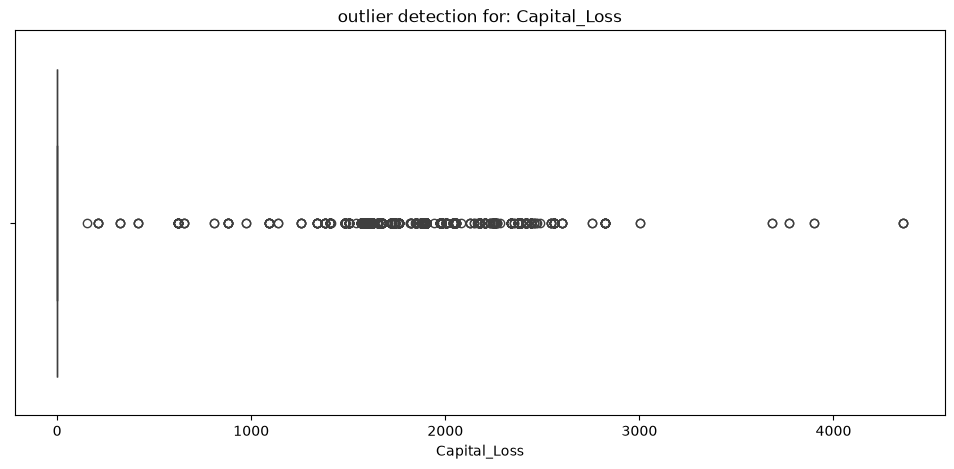

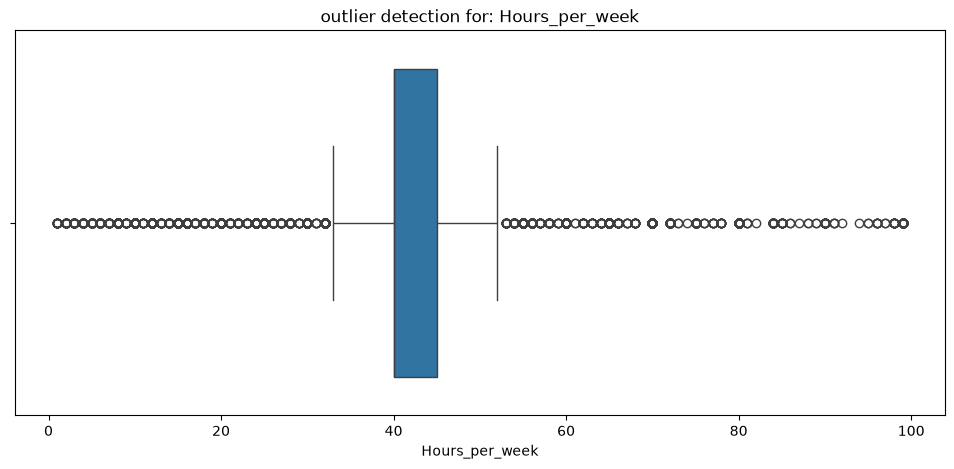

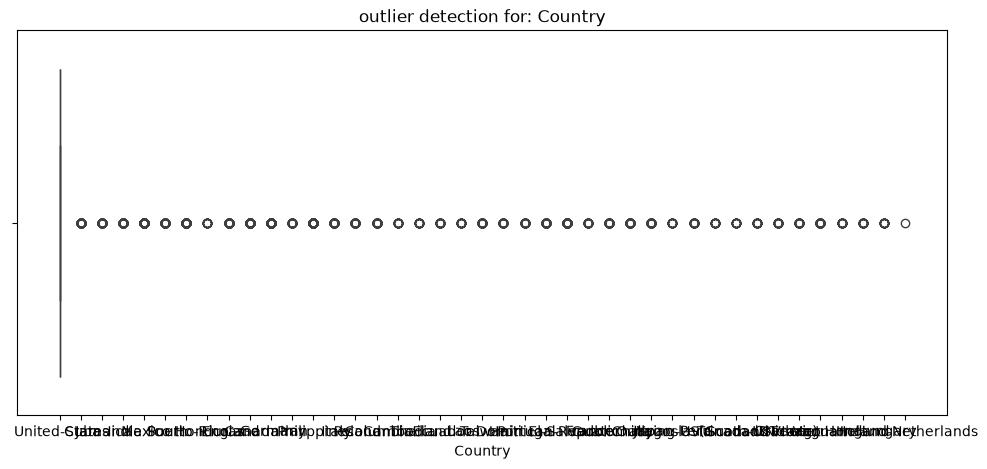

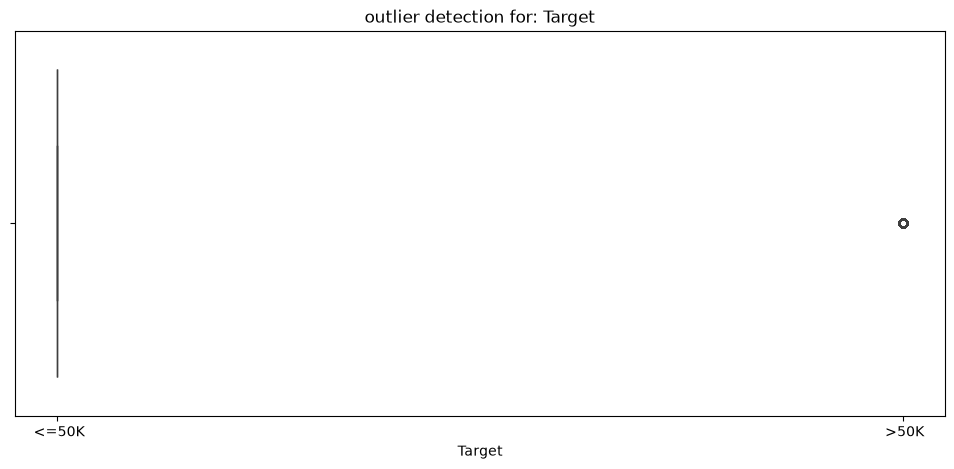

In [329]:
for column in df.columns:
    plt.figure(figsize=(12,5))
    sns.boxplot(data=df, x=column)
    plt.title(f"outlier detection for: {column}")
    plt.show()

In [330]:
for col in df.columns:
    print(col)

Age
Workclass
fnlwgt
Education
Education_Num
Martial_Status
Occupation
Relationship
Race
Sex
Capital_Gain
Capital_Loss
Hours_per_week
Country
Target


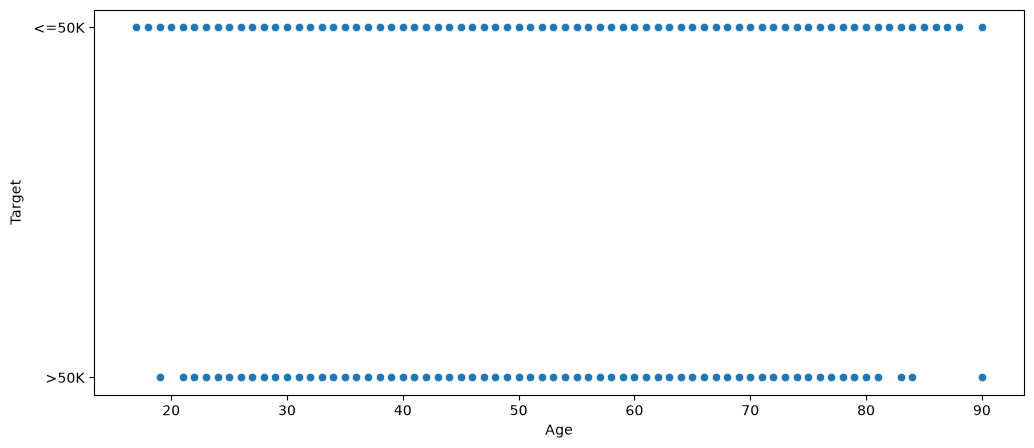

In [331]:
plt.figure(figsize=(12,5))
sns.scatterplot(data=df, x="Age", y="Target")
plt.show()

<Figure size 1200x500 with 0 Axes>

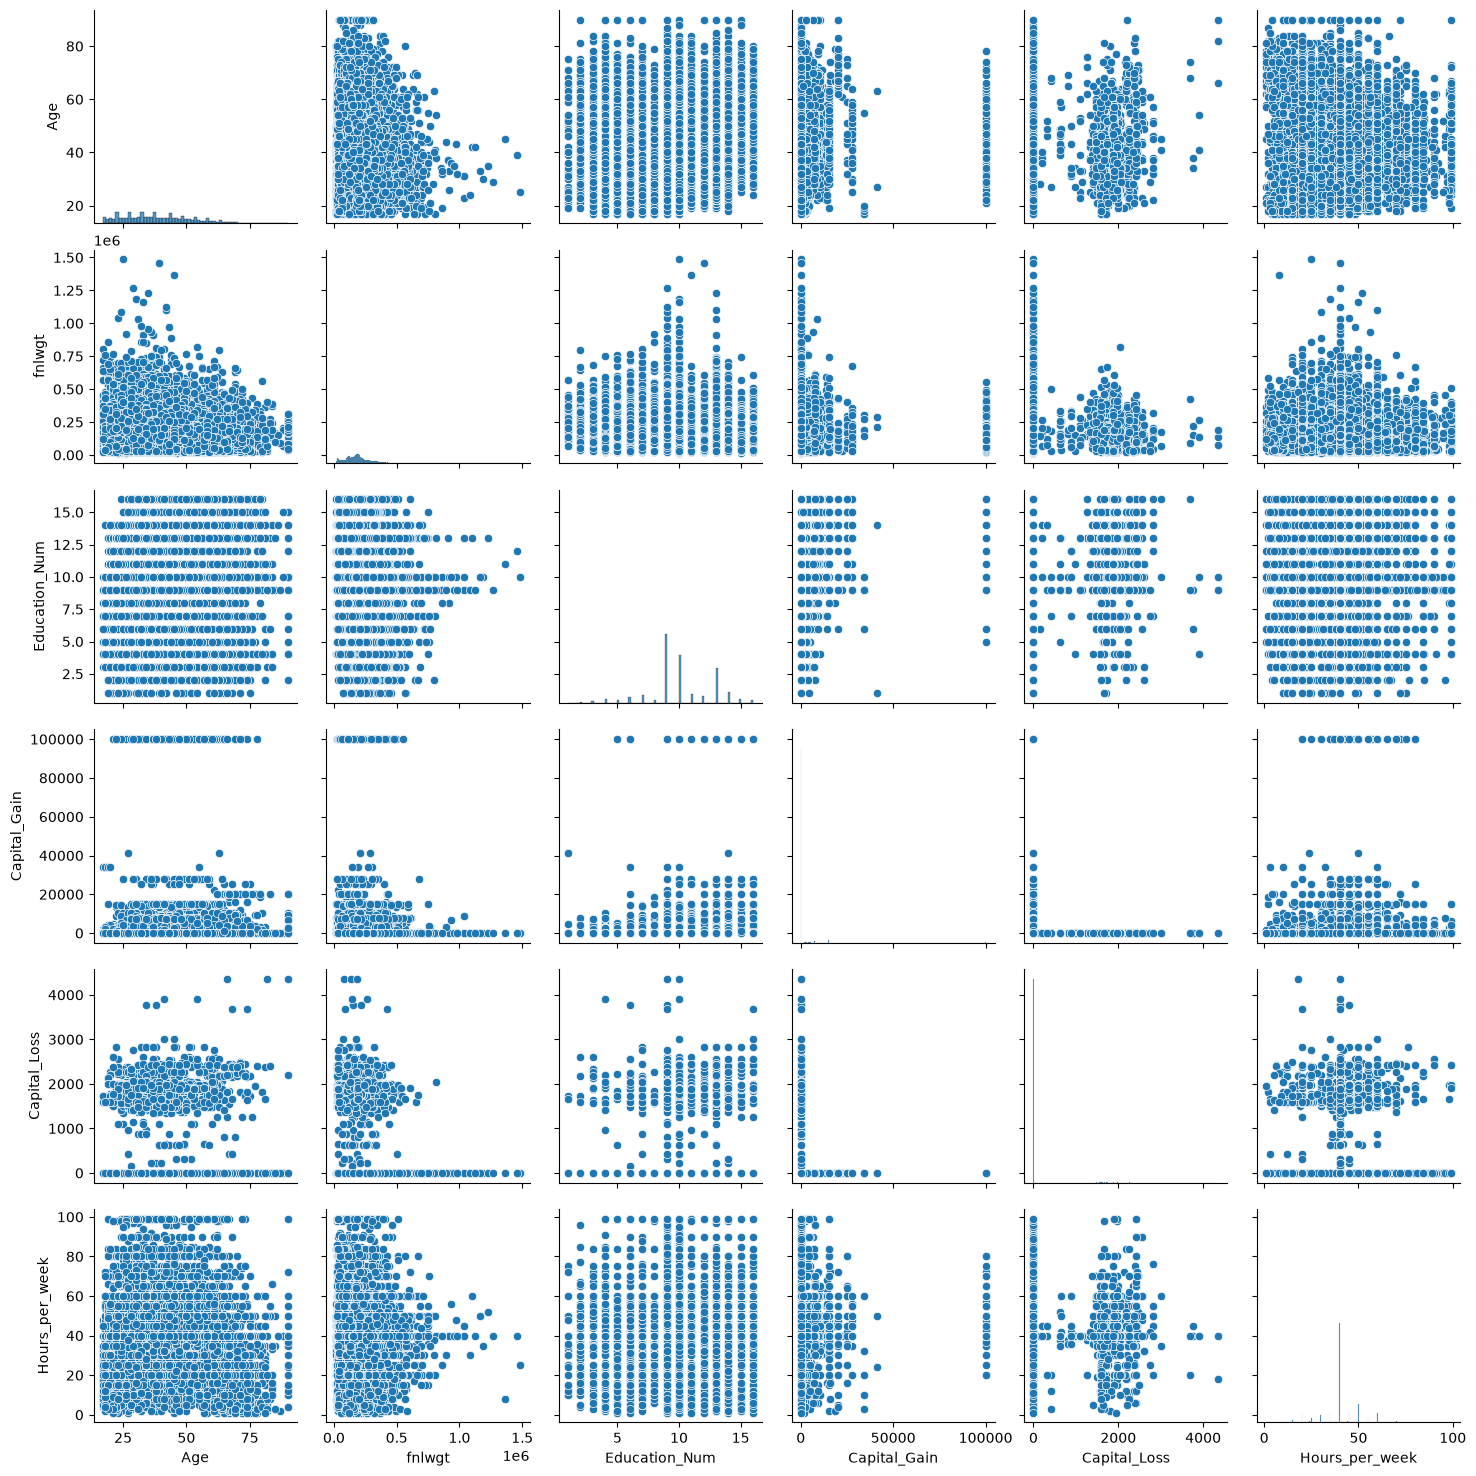

In [332]:
plt.figure(figsize=(12,5))
sns.pairplot(df, vars=numaricle_columns)
plt.show()

In [333]:
def wisper(col):
    Q1 = col.quantile(0.25)
    Q3 = col.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return lower, upper
    

In [334]:
for col in numaricle_columns:
    lower, upper = wisper(df[col])
    df[col] = df[col].clip(lower=lower, upper=upper)


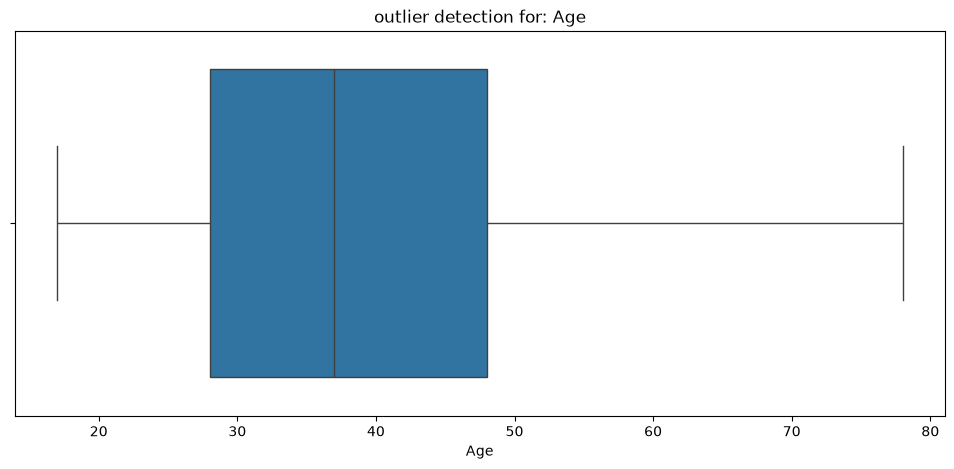

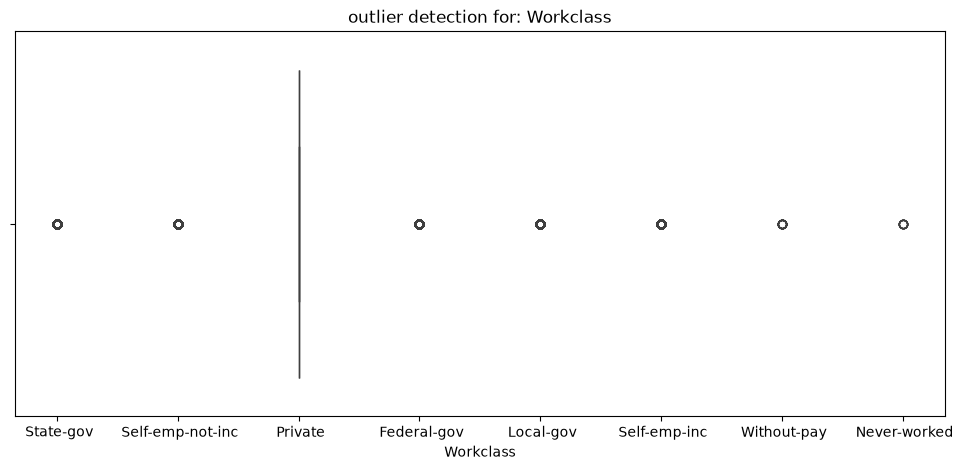

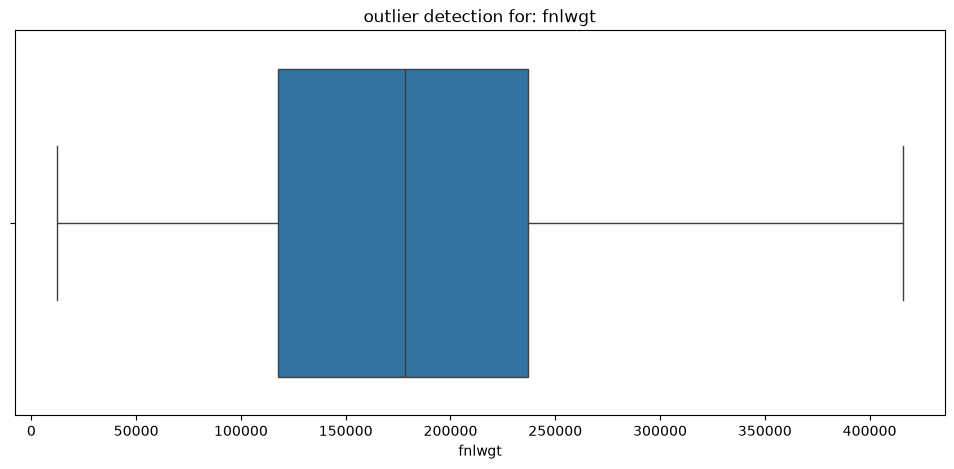

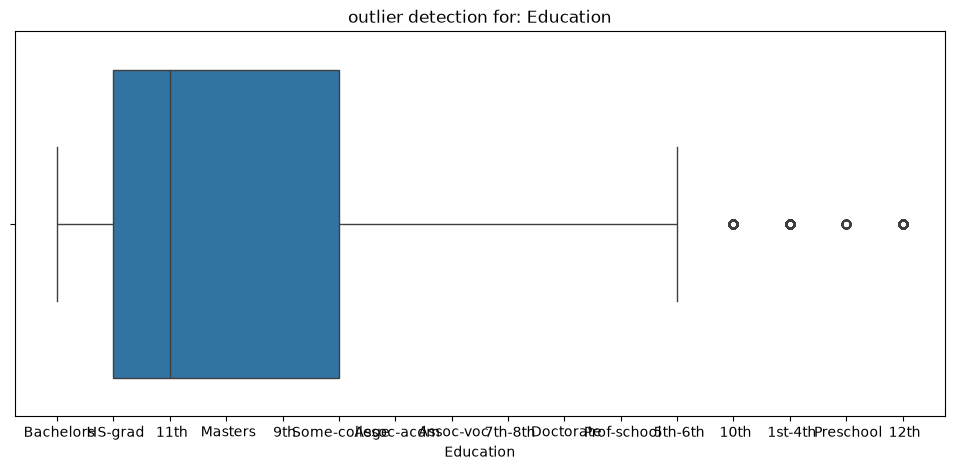

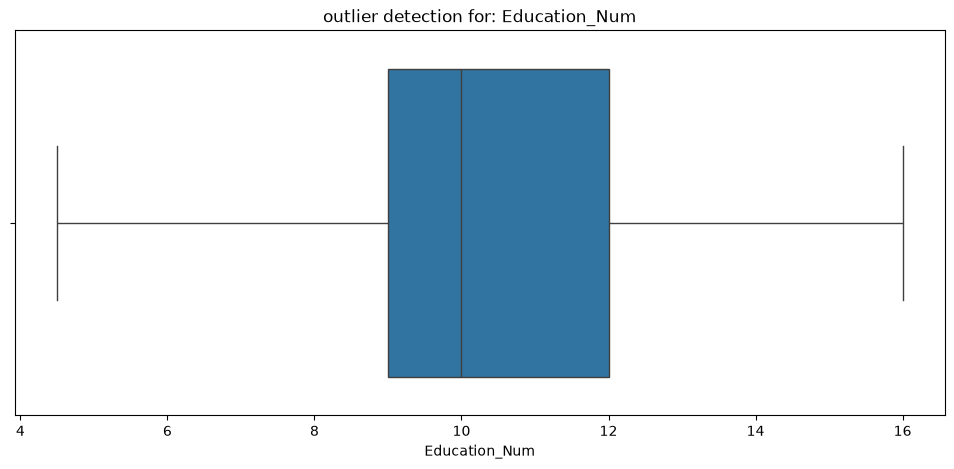

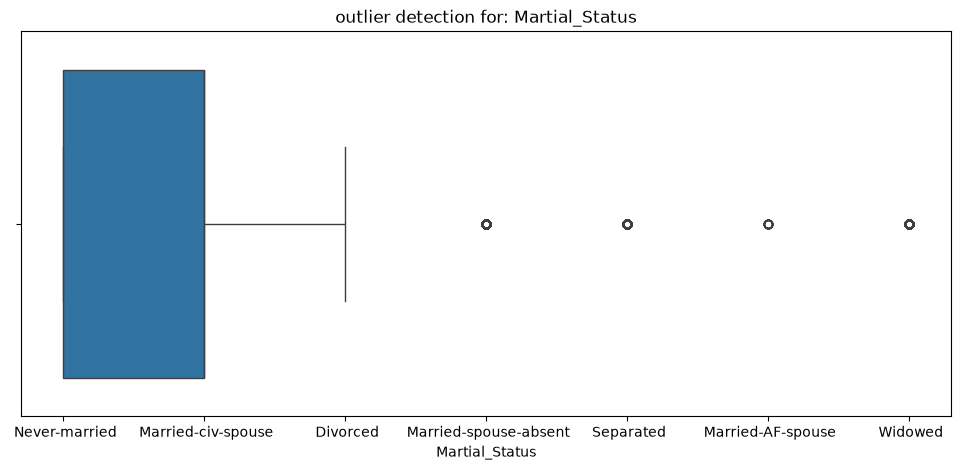

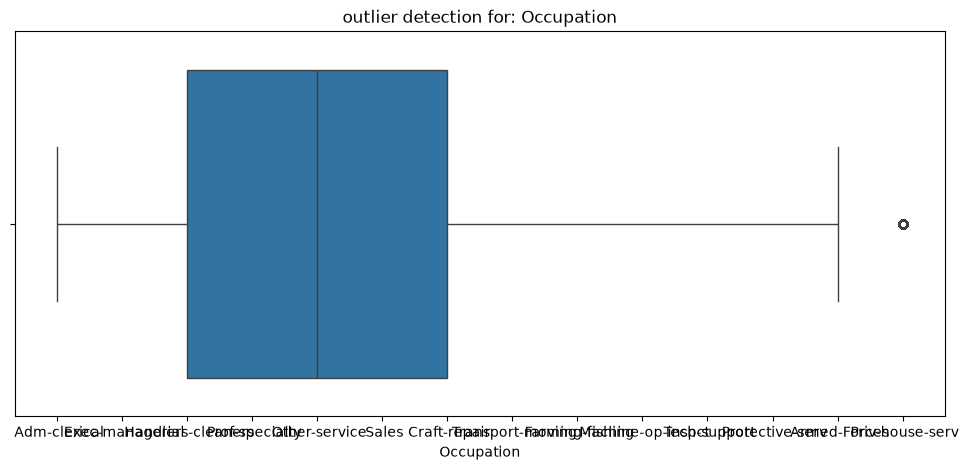

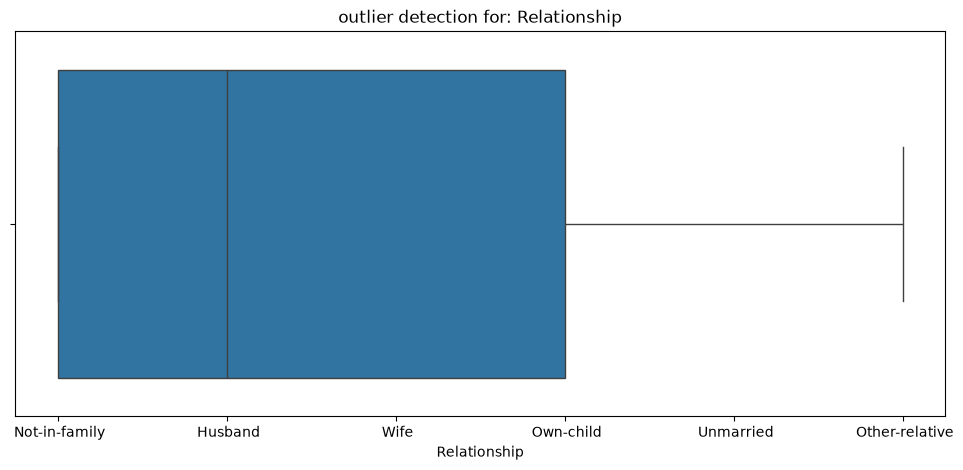

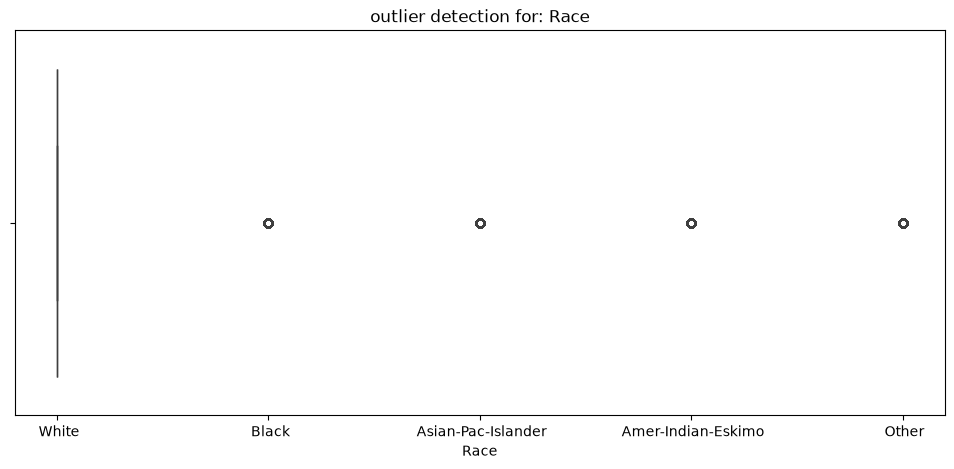

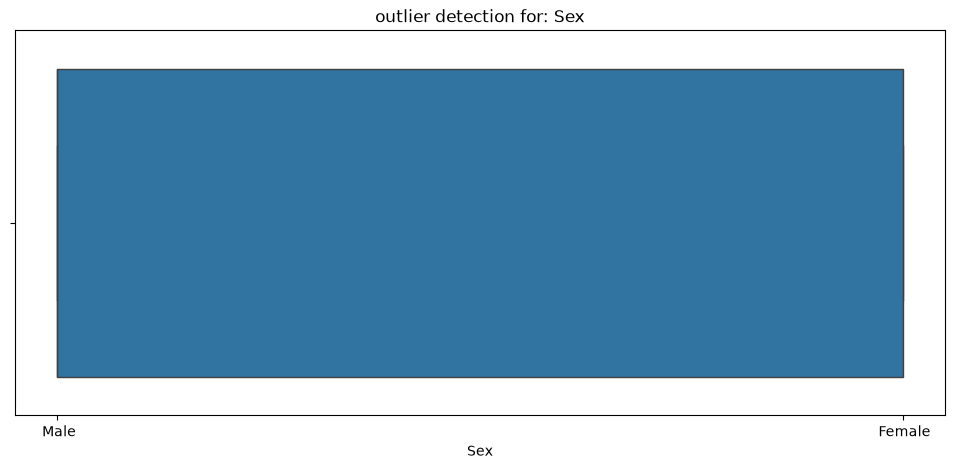

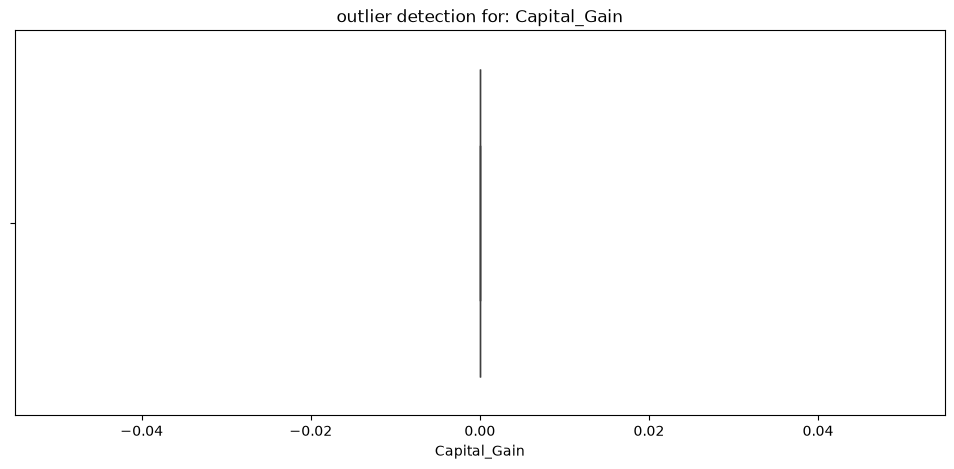

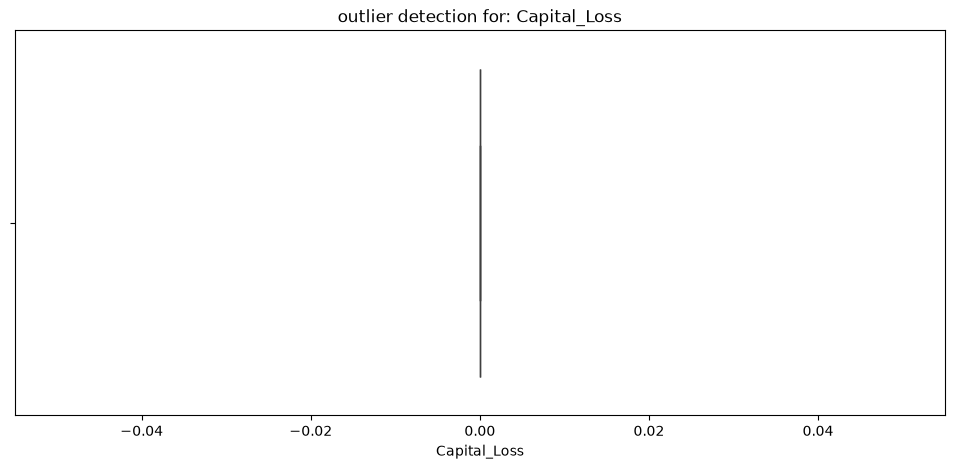

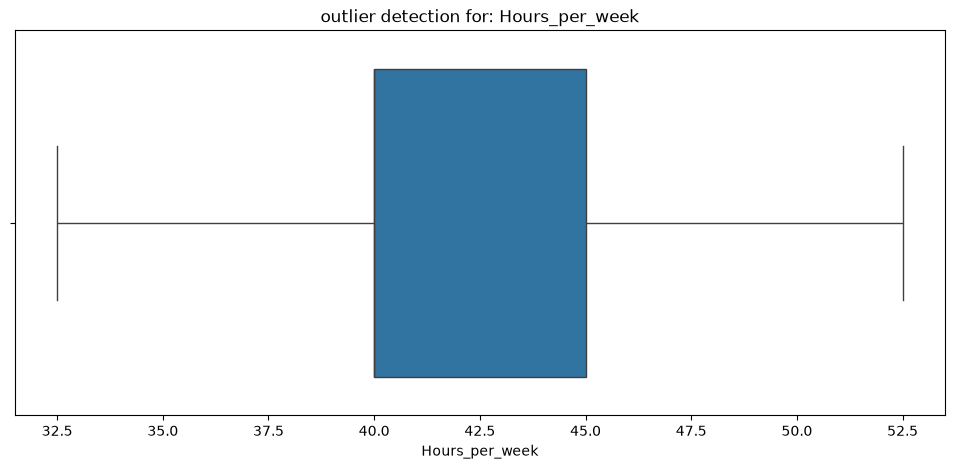

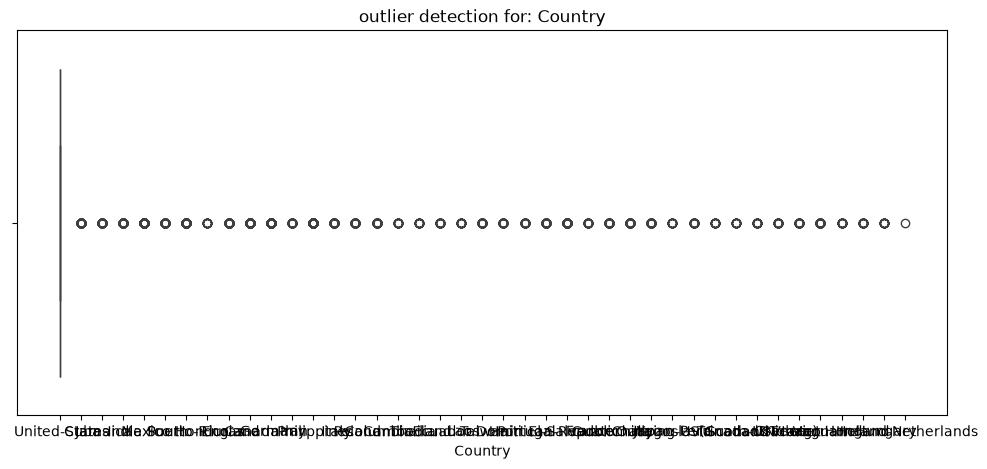

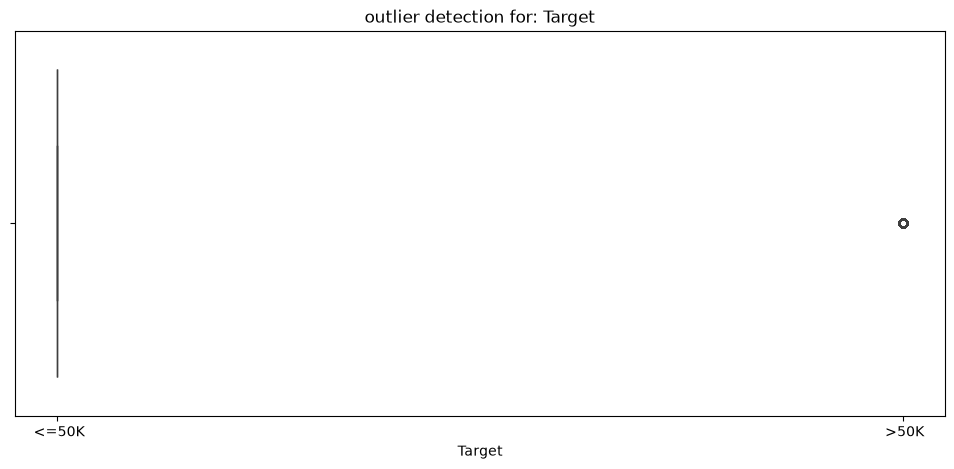

In [335]:
for column in df.columns:
    plt.figure(figsize=(12,5))
    sns.boxplot(data=df, x=column)
    plt.title(f"outlier detection for: {column}")
    plt.show()

In [336]:
categorical_columns = df.select_dtypes(include="str").columns
print(categorical_columns)


Index(['Workclass', 'Education', 'Martial_Status', 'Occupation',
       'Relationship', 'Race', 'Sex', 'Country', 'Target'],
      dtype='str')


In [337]:
numaricle_columns = df.select_dtypes(include=["int64", "float64"]).columns
print(numaricle_columns)

Index(['Age', 'fnlwgt', 'Education_Num', 'Capital_Gain', 'Capital_Loss',
       'Hours_per_week'],
      dtype='str')


In [338]:
df.head(10)

,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country,Target
0,39,State-gov,77516,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,32.5,United-States,<=50K
2,38,Private,215646,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53,Private,234721,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28,Private,338409,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K
5,37,Private,284582,Masters,14.0,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40.0,United-States,<=50K
6,49,Private,160187,9th,5.0,Married-spouse-absent,Other-service,Not-in-family,Black,Female,0,0,32.5,Jamaica,<=50K
7,52,Self-emp-not-inc,209642,HS-grad,9.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45.0,United-States,>50K
8,31,Private,45781,Masters,14.0,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,50.0,United-States,>50K
9,42,Private,159449,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,40.0,United-States,>50K


In [339]:
X = df.drop(columns="Target")
X

,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country
0,39,State-gov,77516,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Male,0,0,40.0,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13.0,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,32.5,United-States
2,38,Private,215646,HS-grad,9.0,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States
3,53,Private,234721,11th,7.0,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States
4,28,Private,338409,Bachelors,13.0,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12.0,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38.0,United-States
32557,40,Private,154374,HS-grad,9.0,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40.0,United-States
32558,58,Private,151910,HS-grad,9.0,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40.0,United-States
32559,22,Private,201490,HS-grad,9.0,Never-married,Adm-clerical,Own-child,White,Male,0,0,32.5,United-States


In [340]:
Y = df["Target"]
Y

0         <=50K
1         <=50K
2         <=50K
3         <=50K
4         <=50K
          ...  
32556     <=50K
32557      >50K
32558     <=50K
32559     <=50K
32560      >50K
Name: Target, Length: 32537, dtype: str

In [341]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42, stratify=Y)
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((26029, 14), (6508, 14), (26029,), (6508,))

In [342]:
X_train.head(10)
X_test.head(10)

,Age,Workclass,fnlwgt,Education,Education_Num,Martial_Status,Occupation,Relationship,Race,Sex,Capital_Gain,Capital_Loss,Hours_per_week,Country
20334,27,Private,178709,Masters,14.0,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40.0,United-States
23878,51,Local-gov,387250,Bachelors,13.0,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,50.0,United-States
19996,34,Private,202498,12th,8.0,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40.0,Dominican-Republic
21440,31,Private,133861,Assoc-acdm,12.0,Divorced,Exec-managerial,Not-in-family,White,Male,0,0,40.0,United-States
10000,34,Private,120461,Some-college,10.0,Divorced,Adm-clerical,Not-in-family,White,Female,0,0,50.0,United-States
16397,47,Private,107682,HS-grad,9.0,Divorced,Adm-clerical,Unmarried,White,Female,0,0,48.0,United-States
3400,39,Self-emp-not-inc,174330,Some-college,10.0,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40.0,United-States
8484,36,State-gov,116554,Bachelors,13.0,Never-married,Adm-clerical,Not-in-family,White,Female,0,0,40.0,United-States
2823,18,Local-gov,36411,12th,8.0,Never-married,Prof-specialty,Own-child,White,Male,0,0,32.5,United-States
7275,42,State-gov,104663,Doctorate,16.0,Never-married,Exec-managerial,Not-in-family,White,Female,0,0,40.0,Italy


In [343]:
Y_test.head(10)

20334     <=50K
23878      >50K
19996     <=50K
21440     <=50K
10000     <=50K
16397     <=50K
3400      <=50K
8484      <=50K
2823      <=50K
7275       >50K
Name: Target, dtype: str

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split


X = df.drop(columns="Target")
Y = df["Target"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)


preprocessing = ColumnTransformer([
    ("num", StandardScaler(), numaricle_columns),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
])

# Training data
X_train_process = preprocessing.fit_transform(X_train)

# Testing data
X_test_process = preprocessing.transform(X_test)

(26029, 14) (6508, 14) (26029,) (6508,)


ValueError: Some column names are not columns of the dataframe: {'Target'}

In [ ]:
df.memory_usage()
df.memory_usage().sum()

np.int64(4164736)